# 12 — EDA Temática: Custo Logístico, Diesel e Assimetria Espacial (Hipótese H1)
**Responsável:** Arthur Araujo
**Foco temático:** preços de diesel comum, diesel S10, gasolina, etanol e GLP (ANP) e o sobrecusto regional do diesel (`comb_diesel_vs_br_pct`)
**Base:** `data/processed/fato_alimentos_combustiveis_uf_mes.parquet` (2.088 linhas × 108 colunas, 16 UFs, 2015-01 a 2026-06)
**Disciplina:** SSC0957 — Prática em Ciência de Dados II (Prof. Alexandre Delbem — USP)
**Plano de execução da EDA:** [`docs/planejamento/plano_execucao_eda_grupo.md`](../docs/planejamento/plano_execucao_eda_grupo.md) (Frente 3)
**Referência macroscópica:** [`notebooks/09_eda_fato_uf_mes.ipynb`](09_eda_fato_uf_mes.ipynb) · **Defasagens e síntese:** [`notebooks/14_eda_macro_lags_sintese.ipynb`](14_eda_macro_lags_sintese.ipynb)

---

**Perguntas desta frente** (do plano do grupo):

1. Qual é a magnitude do **sobrecusto do diesel** nos estados do Norte e do Nordeste em relação ao Centro-Sul?
2. Existe **histerese** na transmissão do diesel: o repasse da alta é rápido e o da queda é lento ou incompleto?
3. Como a **greve dos caminhoneiros de 2018** e o **choque de 2022** atingiram as 16 UFs?

E o teste formal da **Hipótese H1** da [Proposta](../docs/Proposta.md): *"Em estados distantes dos polos produtores,
o diesel explica mais de 50 % da variância do preço de alimentos, tornando o clima irrelevante localmente."*

> **Relação com o notebook 14.** O notebook 14 já mediu a CCF do diesel (um platô fraco de `t` a `t−5`, sem passar
> no FDR) e mostrou que o diesel da UF em relação ao Brasil não explica nada na camada regional (|r| ≤ 0,03). Este
> caderno não repete essas contas: parte delas e pergunta **por quê**, olhando a estrutura do próprio preço do
> diesel e testando a H1 UF por UF.

In [1]:
import contextlib
import io
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

# Acha a raiz do repositório, de onde quer que o notebook tenha sido aberto.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))

from src.analise.eda_utils import (
    adicionar_lags_painel,
    carregar_fato_alimentos,
    configurar_estilo_visual,
    salvar_figura,
)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

configurar_estilo_visual()  # estilo compartilhado das EDAs temáticas

# Por cima do estilo compartilhado, a identidade visual dos notebooks 09 e 14: uma cor fixa por família.
CORES = {
    "ipca": "#2a78d6",   # IBGE/SIDRA
    "clima": "#eb6834",  # INMET
    "safra": "#1baf7a",  # IBGE/LSPA
    "seca": "#eda100",   # ANA
    "macro": "#e87ba4",  # BCB
    "comb": "#008300",   # ANP
}
NEUTRO, FUNDO = "#c3c2b7", "#fcfcfb"
TINTA, TINTA_2, TINTA_3 = "#0b0b0b", "#52514e", "#898781"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": NEUTRO, "axes.labelcolor": TINTA_2, "axes.labelweight": "normal", "text.color": TINTA,
    "xtick.color": TINTA_3, "ytick.color": TINTA_3, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9,
    "font.size": 9.5, "lines.linewidth": 2, "legend.frameon": False,
})

FONTES = {
    "ipca": "IBGE/SIDRA, IPCA (tabelas 1419 e 7060)",
    "macro": "BCB/SGS (série 433, deflator)",
    "comb": "ANP, Levantamento de Preços de Combustíveis",
}


def finalizar(fig, nome, *familias):
    """Carimba a fonte no rodapé e salva em outputs/figuras/eda/ (150 DPI) pelo utilitário do grupo."""
    texto = "Fonte: " + "; ".join(FONTES[f] for f in familias) + ". Elaboração: Grupo 1 (SSC0957)."
    fig.text(0.0, -0.01, texto, ha="left", va="top", fontsize=7.5, color=TINTA_3)
    with contextlib.redirect_stdout(io.StringIO()):  # o utilitário imprime o caminho absoluto da máquina
        caminho = salvar_figura(fig, nome, dpi=150)
    print(f"figura salva: {caminho.relative_to(RAIZ)}")


def eixo_tempo(ax, passo=1):
    ax.xaxis.set_major_locator(mdates.YearLocator(passo))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(axis="x", visible=False)


# Os episódios que importam para a logística (mesmas datas do notebook 14).
EVENTOS = [
    ("2018-05", "2018-06", "greve", 0.97),
    ("2020-03", "2021-03", "pandemia + câmbio", 0.97),
    ("2022-03", "2022-07", "guerra + diesel", 0.97),
]


def marcar_eventos(ax, rotulos=True):
    for ini, fim, nome, y in EVENTOS:
        a = pd.Period(ini, "M").to_timestamp()
        b = pd.Period(fim, "M").to_timestamp(how="end")
        ax.axvspan(a, b, color="#efeee9", zorder=0, linewidth=0)
        if rotulos:
            ax.text(a, y, " " + nome, transform=ax.get_xaxis_transform(), ha="left", va="top",
                    fontsize=7.5, color=TINTA_2)


print(f"raiz do projeto: {RAIZ.name}/")

raiz do projeto: trabalho_pcd2/


In [2]:
fato = carregar_fato_alimentos()
ALVO = "ipca_var_alimentacao"

assert fato.shape == (2088, 108), f"esperava 2.088 × 108, veio {fato.shape}"
assert not fato.duplicated(["sigla_uf", "ano_mes"]).any(), "chave (sigla_uf, ano_mes) duplicada"
# Defasar por linha (groupby.shift) só equivale a defasar por mês se não faltar mês dentro de nenhuma UF.
assert fato.groupby("sigla_uf")["ano_mes"].apply(lambda s: (s.astype("int64").diff().dropna() == 1).all()).all()

fato["mes_cal"] = fato["ano_mes"].dt.month
fato["data"] = fato["ano_mes"].dt.to_timestamp()
MESES = pd.period_range(fato["ano_mes"].min(), fato["ano_mes"].max(), freq="M")
REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
ufs = fato[["sigla_uf", "regiao"]].drop_duplicates()
ufs["ordem"] = ufs["regiao"].map({r: i for i, r in enumerate(REGIOES)})
ORDEM_UF = ufs.sort_values(["ordem", "sigla_uf"])["sigla_uf"].tolist()
REGIAO_DA_UF = dict(zip(ufs["sigla_uf"], ufs["regiao"]))

# Os grupos da H1, como o plano do grupo os define: estados remotos × Centro-Sul.
REMOTOS = ["AC", "PA", "MA"]
CENTRO_SUL = [u for u in ORDEM_UF if REGIAO_DA_UF[u] in ("Centro-Oeste", "Sudeste", "Sul")]
G_REM, G_CS, G_NE = "remotos (AC, PA, MA)", "Centro-Sul", "demais do Nordeste"
GRUPO = {u: G_REM if u in REMOTOS else G_CS if u in CENTRO_SUL else G_NE for u in ORDEM_UF}
CORES_GRUPO = {G_REM: "#eb6834", G_CS: "#2a78d6", G_NE: NEUTRO}

# Janela contínua da ANP: de 2021-07 em diante não falta nenhum mês de combustível líquido.
JANELA = (pd.Period("2021-07", "M"), pd.Period("2026-06", "M"))
assert fato.loc[fato["ano_mes"].between(*JANELA), "comb_observado_liquidos"].all()

# Deflator: IPCA geral (nacional). Preço real = R$ de 2026-06.
ipca = fato.drop_duplicates("ano_mes").set_index("ano_mes")["macro_ipca_mm"].sort_index()
nivel = (1 + ipca / 100).cumprod()
fato["deflator"] = fato["ano_mes"].map(nivel.iloc[-1] / nivel)

display(pd.DataFrame({g: [", ".join(u for u in ORDEM_UF if GRUPO[u] == g)] for g in CORES_GRUPO}, index=["UFs"]).T)

,UFs
"remotos (AC, PA, MA)","AC, PA, MA"
Centro-Sul,"DF, GO, MS, ES, MG, RJ, SP, PR, RS"
demais do Nordeste,"BA, CE, PE, SE"


---
## 0. Auditoria e confronto com a EDA geral (notebook 09)

> **Ponto de partida do notebook 09:** diesel e GLP em 12 meses têm as correlações contemporâneas mais altas com a
> inflação de alimentos em 12 meses (ρ = 0,46 e 0,68, a partir de 2020). O notebook 14 mostrou que elas caem para
> +0,17 e +0,19 em variação mensal e não passam no FDR em nenhum lag: eram ciclo compartilhado.
>
> **Pergunta norteadora:** se o diesel é o custo do frete, e o frete é mais caro longe dos polos produtores, por que
> o diesel não explica a diferença entre UFs? A resposta começa na estrutura do próprio preço do diesel.

### 0.1 Os números de partida se reproduzem?

In [3]:
def spearman(df, x, y):
    par = df[[x, y]].dropna()
    r = stats.spearmanr(par[x], par[y])
    return r.statistic, r.pvalue, len(par)


ACUM12 = "ipca_var_alimentacao_acum12"
desde20 = fato[fato["ano_mes"] >= pd.Period("2020-01", "M")]
linhas = []
for nome, x, y, ref in [("Diesel em 12 meses × alimentação em 12 meses", "comb_var12_diesel", ACUM12, 0.46),
                        ("GLP em 12 meses × alimentação em 12 meses", "comb_var12_glp_13kg", ACUM12, 0.68),
                        ("Diesel no mês × alimentação no mês", "comb_var_mm_diesel", ALVO, None)]:
    rho, p, n = spearman(desde20, x, y)
    linhas.append({"par (painel UF × mês, desde 2020-01)": nome, "ρ do notebook 09": ref, "ρ aqui": round(rho, 2), "n": n})
display(pd.DataFrame(linhas))

,"par (painel UF × mês, desde 2020-01)",ρ do notebook 09,ρ aqui,n
0,Diesel em 12 meses × alimentação em 12 meses,0.46,0.46,1049
1,GLP em 12 meses × alimentação em 12 meses,0.68,0.68,1216
2,Diesel no mês × alimentação no mês,NaN,0.16,1146


**Leitura:** os dois números do notebook 09 conferem (0,46 e 0,68). No mês, sem acumular 12 meses, o diesel cai
para ~0,19, a ordem de grandeza que o notebook 14 encontrou.

### 0.2 Quanto do preço do diesel é "do Brasil" e quanto é "da UF"?

É a mesma conta que o notebook 09 fez para o alvo: a parcela da variância explicada só pelo mês (efeito comum a
todas as UFs) e só pela UF (nível próprio de cada UF).

In [4]:
def parcelas(col):
    s = fato[col]
    ok = s.notna()
    s, mes, uf = s[ok], fato.loc[ok, "ano_mes"], fato.loc[ok, "sigla_uf"]
    total = ((s - s.mean()) ** 2).sum()
    so_mes = 1 - ((s - s.groupby(mes).transform("mean")) ** 2).sum() / total
    so_uf = 1 - ((s - s.groupby(uf).transform("mean")) ** 2).sum() / total
    return {"explicado só pelo mês (%)": so_mes * 100, "explicado só pela UF (%)": so_uf * 100, "UF-meses": int(ok.sum())}


SERIES = {
    "Inflação de alimentos no mês (o alvo)": ALVO,
    "Diesel: variação no mês": "comb_var_mm_diesel",
    "Gasolina: variação no mês": "comb_var_mm_gasolina",
    "Etanol: variação no mês": "comb_var_mm_etanol",
    "GLP: variação no mês": "comb_var_mm_glp_13kg",
    "Diesel: preço (R$/L, nominal)": "comb_preco_diesel",
    "Diesel da UF vs. Brasil (%)": "comb_diesel_vs_br_pct",
}
decomp = pd.DataFrame({nome: parcelas(col) for nome, col in SERIES.items()}).T
decomp[["explicado só pelo mês (%)", "explicado só pela UF (%)"]] = decomp[
    ["explicado só pelo mês (%)", "explicado só pela UF (%)"]].astype(float).round(1)
display(decomp)
print(f"correlação entre a variação mensal do diesel comum e a do S10: "
      f"{fato['comb_var_mm_diesel'].corr(fato['comb_var_mm_diesel_s10']):.3f}")

,explicado só pelo mês (%),explicado só pela UF (%),UF-meses
Inflação de alimentos no mês (o alvo),73.2,0.1,2088.0
Diesel: variação no mês,89.6,0.0,1463.0
Gasolina: variação no mês,84.2,0.1,1467.0
Etanol: variação no mês,71.0,0.1,1467.0
GLP: variação no mês,69.7,0.2,1811.0
"Diesel: preço (R$/L, nominal)",95.8,6.7,1610.0
Diesel da UF vs. Brasil (%),1.1,81.7,1610.0


correlação entre a variação mensal do diesel comum e a do S10: 0.980


**Leitura:** o preço do diesel tem **duas partes com comportamentos opostos**.

- **A variação é nacional.** 89,6 % da variância da variação mensal do diesel é explicada só pelo mês, e 0,0 % pela
  UF. O mesmo vale para gasolina (84 %), etanol (71 %) e GLP (70 %). Quando o diesel sobe, sobe no país inteiro e quase
  na mesma proporção, o que é coerente com um preço de refinaria definido nacionalmente. O diesel S10 anda junto com o
  comum (r = 0,98), por isso fica de fora daqui em diante.
- **O sobrecusto é da UF.** O desvio do diesel da UF em relação ao Brasil é o contrário: 81,7 % é característica
  fixa da UF, e só 1,1 % muda com o mês.

**Consequência para todo o resto do notebook.** O notebook 14 mostrou que 27 % da variância da inflação de alimentos
é regional, isto é, é a diferença entre UFs no mesmo mês. A **variação** do diesel não pode explicar essa parte,
porque é quase igual em todas as UFs. O **sobrecusto** varia entre UFs, mas é quase constante no tempo, e uma
constante não explica uma **variação** de preço. Por isso o diesel relativo do notebook 14 dá |r| ≤ 0,03. O sobrecusto
deveria aparecer no **nível** do preço da comida, que o IPCA não mede.

### 0.3 Os 33 meses sem pesquisa: de onde vêm?

A ANP não tem preço de combustível líquido em 33 dos 138 meses, nos mesmos meses para todas as UFs. Antes de
interpretar qualquer coisa, conferimos se o buraco nasce na fonte ou no nosso tratamento, e como ele se distribui no
tempo.

In [5]:
sem = (~fato.groupby("ano_mes")["comb_observado_liquidos"].any()).reindex(MESES)
faltam = sem[sem].index
# Agrupa meses consecutivos em trechos.
trechos, ini, ant = [], None, None
for m in faltam:
    if ini is None or m != ant + 1:
        if ini is not None:
            trechos.append((ini, ant))
        ini = m
    ant = m
trechos.append((ini, ant))
print(f"{len(faltam)} meses sem pesquisa de combustível líquido, em {len(trechos)} trechos:")
print("  " + " · ".join(f"{a}" if a == b else f"{a} a {b}" for a, b in trechos))
print(f"maior trecho contínuo COM pesquisa: {JANELA[0]} a {JANELA[1]} ({len(pd.period_range(*JANELA, freq='M'))} meses)")

bruto = RAIZ / "data" / "raw" / "combustiveis" / "combustivel.csv"
if bruto.exists():
    raw = pd.read_csv(bruto, usecols=["ano_mes", "produto", "sigla_uf"])
    meses_raw = set(pd.PeriodIndex(raw.loc[raw["produto"] == "Diesel", "ano_mes"], freq="M"))
    no_bruto = [m for m in faltam if m in meses_raw]
    print(f"\nno CSV bruto da ANP ({bruto.relative_to(RAIZ)}), desses {len(faltam)} meses, "
          f"{len(no_bruto)} têm diesel: o buraco já vem da fonte, não do tratamento.")
else:
    print("\n(CSV bruto não encontrado neste computador; a checagem da origem do buraco foi pulada)")

reg = fato.groupby(fato["ano_mes"].dt.year)["comb_n_registros"].sum()
print("\ncoletas de preço por ano (5 produtos, 16 UFs), só nos meses com pesquisa:")
print("  " + " · ".join(f"{a}: {int(v):,}".replace(",", ".") for a, v in reg.items()))

33 meses sem pesquisa de combustível líquido, em 9 trechos:
  2015-03 a 2015-06 · 2015-09 a 2015-12 · 2016-03 a 2016-06 · 2016-08 a 2016-12 · 2018-04 a 2018-06 · 2018-08 a 2018-12 · 2019-03 a 2019-06 · 2020-09 · 2021-04 a 2021-06
maior trecho contínuo COM pesquisa: 2021-07 a 2026-06 (60 meses)

no CSV bruto da ANP (data/raw/combustiveis/combustivel.csv), desses 33 meses, 0 têm diesel: o buraco já vem da fonte, não do tratamento.

coletas de preço por ano (5 produtos, 16 UFs), só nos meses com pesquisa:
  2015: 370.428 · 2016: 369.047 · 2017: 731.740 · 2018: 331.347 · 2019: 727.450 · 2020: 720.961 · 2021: 505.129 · 2022: 750.667 · 2023: 737.126 · 2024: 731.030 · 2025: 631.782 · 2026: 321.776


**Leitura:** os 33 meses sem pesquisa formam 9 trechos, todos antes de 2021-07, e **nenhum deles tem diesel no CSV
bruto da ANP**: a falha vem da fonte, não do nosso tratamento. Três consequências:

- **A greve de 2018** (maio) cai num buraco de 2018-04 a 2018-06, e o 2º semestre de 2018 também falta.
- **O único trecho contínuo** vai de 2021-07 a 2026-06 (60 meses). É nele que qualquer defasagem ou variação de
  combustível pode ser medida sem furos.
- **A soma anual de coletas** cai nos anos com meses sem pesquisa (2015, 2016, 2018) e em 2026, que só tem seis
  meses. Mede quanto o preço foi observado, não o preço.

---
## 1. Comportamento principal & sazonalidade

> **Objetivo:** a evolução secular do diesel ponderado pelo número de postos pesquisados, em R$ correntes e em R$
> constantes, ao lado dos outros combustíveis; a sazonalidade; e a sensibilidade das conclusões aos 33 meses sem
> pesquisa.

O preço de cada UF já vem da junção como **média ponderada pelo número de postos pesquisados**. O painel A mostra a
mediana das 16 UFs e a faixa entre elas, com as UFs remotas em destaque. Os tracinhos no pé do painel marcam os
meses sem pesquisa: as linhas são interrompidas ali, de propósito, porque não interpolamos.

figura salva: outputs/figuras/eda/fig_12_01_trajetoria_diesel_ponderado_postos.png


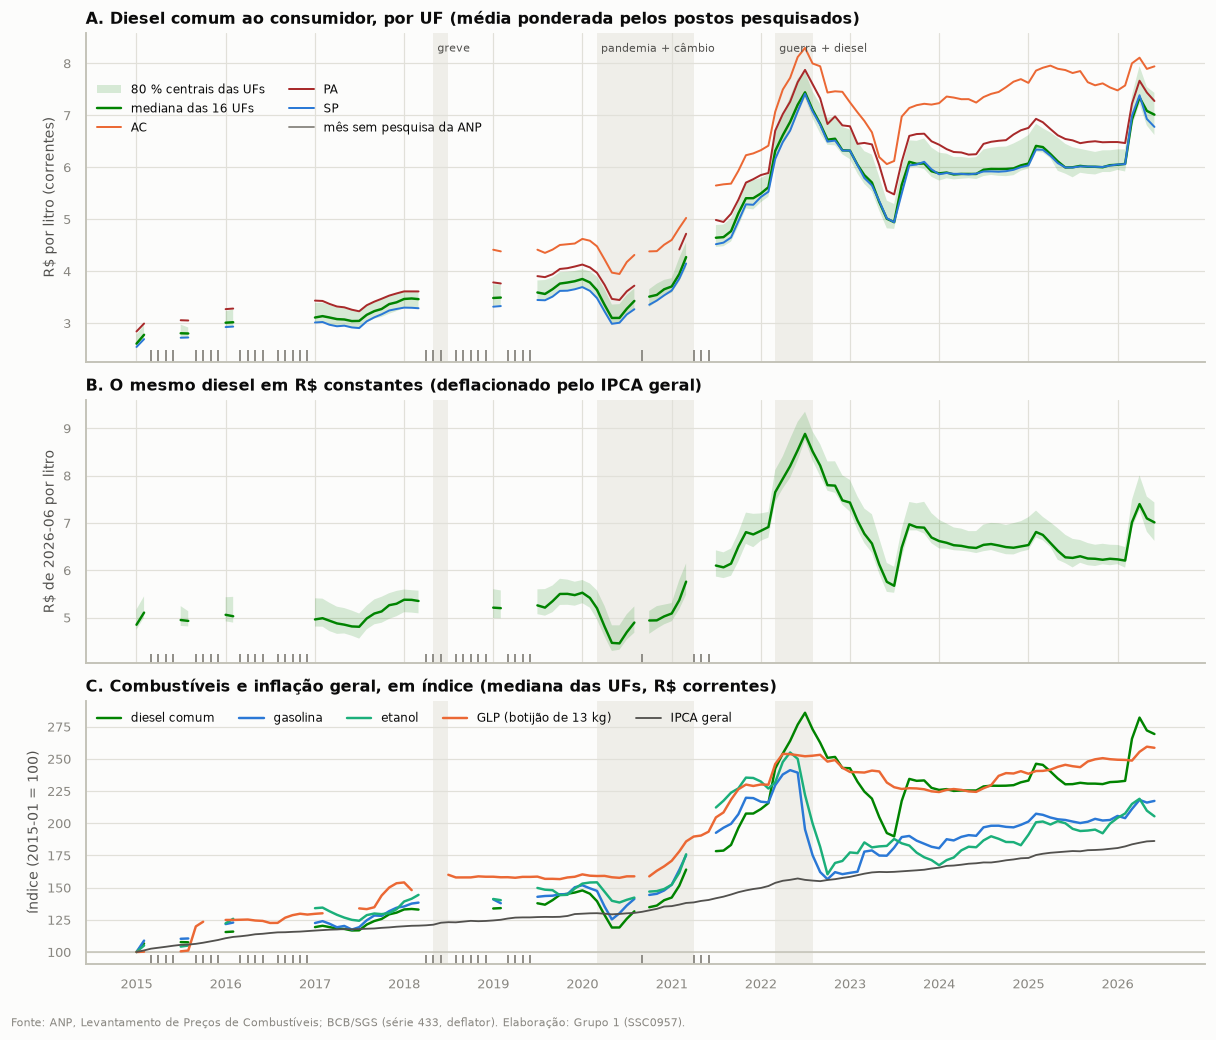

alta acumulada de 2015-01 a 2026-06 (mediana das UFs, R$ correntes): {'diesel comum': '169 %', 'gasolina': '117 %', 'etanol': '105 %', 'GLP (botijão de 13 kg)': '159 %'} · IPCA geral: 86 %
diesel real: R$ 4.85 em 2015-01, pico de R$ 8.88 em 2022-07, R$ 7.01 em 2026-06 (R$ de 2026-06)


In [6]:
diesel = fato.pivot(index="data", columns="sigla_uf", values="comb_preco_diesel")
diesel_real = fato.assign(v=fato["comb_preco_diesel"] * fato["deflator"]).pivot(index="data", columns="sigla_uf", values="v")
q = diesel.quantile([0.1, 0.5, 0.9], axis=1).T
q_real = diesel_real.quantile([0.1, 0.5, 0.9], axis=1).T
sem_datas = faltam.to_timestamp()

PRODUTOS = {"comb_preco_diesel": ("diesel comum", CORES["comb"]), "comb_preco_gasolina": ("gasolina", "#2a78d6"),
            "comb_preco_etanol": ("etanol", "#1baf7a"), "comb_preco_glp_13kg": ("GLP (botijão de 13 kg)", "#eb6834")}
med_prod = fato.groupby("data")[list(PRODUTOS)].median()
base = med_prod.loc["2015-01-01"]
indice = med_prod / base * 100

DESTAQUE = {"AC": CORES_GRUPO[G_REM], "PA": "#a8292a", "SP": CORES_GRUPO[G_CS]}
fig, axes = plt.subplots(3, 1, figsize=(11, 9.2), sharex=True, gridspec_kw={"height_ratios": [1.25, 1, 1]})
for i, ax in enumerate(axes):
    marcar_eventos(ax, rotulos=(i == 0))
    ax.vlines(sem_datas, 0, 0.035, transform=ax.get_xaxis_transform(), color=TINTA_3, linewidth=1.2)

ax = axes[0]
ax.fill_between(q.index, q[0.1], q[0.9], color=CORES["comb"], alpha=0.15, linewidth=0, label="80 % centrais das UFs")
ax.plot(q.index, q[0.5], color=CORES["comb"], linewidth=1.6, label="mediana das 16 UFs")
for uf, cor in DESTAQUE.items():
    ax.plot(diesel.index, diesel[uf], color=cor, linewidth=1.3, label=uf)
ax.set_ylabel("R$ por litro (correntes)")
ax.set_title("A. Diesel comum ao consumidor, por UF (média ponderada pelos postos pesquisados)")
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], color=TINTA_3, linewidth=1.2))
labels.append("mês sem pesquisa da ANP")
ax.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.0, 0.88), ncol=2, fontsize=8)

ax = axes[1]
ax.fill_between(q_real.index, q_real[0.1], q_real[0.9], color=CORES["comb"], alpha=0.15, linewidth=0)
ax.plot(q_real.index, q_real[0.5], color=CORES["comb"], linewidth=1.6)
ax.set_ylabel("R$ de 2026-06 por litro")
ax.set_title("B. O mesmo diesel em R$ constantes (deflacionado pelo IPCA geral)")

ax = axes[2]
ax.axhline(100, color=NEUTRO, linewidth=1)
for col, (nome, cor) in PRODUTOS.items():
    ax.plot(indice.index, indice[col], color=cor, linewidth=1.6, label=nome)
geral = (nivel / nivel.iloc[0] * 100).set_axis(nivel.index.to_timestamp())
ax.plot(geral.index, geral, color=TINTA_2, linewidth=1.2, label="IPCA geral")
ax.set_ylabel("índice (2015-01 = 100)")
ax.set_title("C. Combustíveis e inflação geral, em índice (mediana das UFs, R$ correntes)")
ax.legend(loc="upper left", ncol=5, fontsize=8)
eixo_tempo(axes[-1])
plt.tight_layout()
finalizar(fig, "fig_12_01_trajetoria_diesel_ponderado_postos", "comb", "macro")
plt.show()

fim = med_prod.loc["2026-06-01"]
print("alta acumulada de 2015-01 a 2026-06 (mediana das UFs, R$ correntes):",
      {PRODUTOS[c][0]: f"{(fim[c] / base[c] - 1) * 100:.0f} %" for c in PRODUTOS},
      f"· IPCA geral: {(nivel.iloc[-1] / nivel.iloc[0] - 1) * 100:.0f} %")
pico_real = q_real[0.5].idxmax()
print(f"diesel real: R$ {q_real[0.5].iloc[0]:.2f} em 2015-01, pico de R$ {q_real[0.5].max():.2f} em {pico_real:%Y-%m}, "
      f"R$ {q_real[0.5].iloc[-1]:.2f} em 2026-06 (R$ de 2026-06)")

**Leitura (`fig_12_01`):**

- **Em R$ correntes** (painel A), o diesel subiu **169 %** de 2015-01 a 2026-06 (mediana das UFs), contra 86 % do
  IPCA geral. Foi o combustível que mais subiu: GLP 159 %, gasolina 117 %, etanol 105 %.
- **Em R$ constantes** (painel B), o diesel foi de R\$ 4,85 (2015-01) a um pico de **R\$ 8,88 em 2022-07**, e está
  em R\$ 7,01 em 2026-06. Mesmo depois da queda, ficou ~45 % mais caro em termos reais que em 2015. O choque de 2022
  é, de longe, o maior evento da série.
- **A faixa entre as UFs é estreita.** O AC está sempre acima dela, o PA logo acima da mediana e SP logo abaixo. É a
  imagem da Seção 0.2: todas as UFs sobem e descem juntas, cada uma no seu patamar.
- **Os combustíveis se separam em 2022** (painel C). Gasolina e etanol caem bruscamente em meados de 2022, o que
  coincide com o teto do ICMS sobre combustíveis; o diesel segue até o pico de julho. O GLP sobe em degraus (2017-18
  e 2021) e depois fica num patamar.

### 1.1 Sazonalidade e sensibilidade aos meses sem pesquisa

Duas checagens que o plano pede:

1. O diesel tem **sazonalidade**? (Kruskal-Wallis da variação mensal entre os meses do ano.)
2. A correlação diesel × comida **muda** quando usamos só a janela contínua? Comparamos três amostras: todos os
   meses com pesquisa, só a janela contínua (2021-07 em diante) e os meses com pesquisa **antes** dela.

In [7]:
# Um ponto por mês (mediana das UFs): a variação do diesel é quase toda nacional, e contar cada mês 16 vezes
# inflaria o teste.
def kruskal_mensal(col):
    s = fato.groupby("ano_mes")[col].median().dropna()
    return stats.kruskal(*[g.values for _, g in s.groupby(s.index.month)]), len(s)


for col, nome in [("comb_var_mm_diesel", "diesel"), ("comb_var_mm_glp_13kg", "GLP"), (ALVO, "alimentação (o alvo)")]:
    kw, n = kruskal_mensal(col)
    print(f"Kruskal-Wallis da variação mensal entre os meses do ano, {nome}: H = {kw.statistic:.1f}, p = {kw.pvalue:.3f} ({n} meses)")
media_mes = fato.groupby("ano_mes")["comb_var_mm_diesel"].median().dropna()
media_mes = media_mes.groupby(media_mes.index.month).mean()
print("variação média do diesel por mês do ano (%):", {m: round(v, 1) for m, v in media_mes.items()})

# Uma série nacional por mês (mediana das UFs): 12 meses de diesel contra 12 meses de comida.
nac = fato.groupby("ano_mes")[["comb_var12_diesel", ACUM12, "comb_var_mm_diesel", ALVO]].median()
AMOSTRAS = {
    "todos os meses com pesquisa": nac.index >= MESES[0],
    "só a janela contínua (2021-07 em diante)": nac.index >= JANELA[0],
    "só antes da janela contínua": nac.index < JANELA[0],
}
linhas = []
for nome, filtro in AMOSTRAS.items():
    for rot, x, y in [("12 meses", "comb_var12_diesel", ACUM12), ("no mês", "comb_var_mm_diesel", ALVO)]:
        par = nac.loc[filtro, [x, y]].dropna()
        r = stats.spearmanr(par[x], par[y])
        linhas.append({"amostra": nome, "versão": rot, "ρ (1 ponto por mês)": round(r.statistic, 2),
                       "meses": len(par)})
display(pd.DataFrame(linhas).pivot(index="amostra", columns="versão", values=["ρ (1 ponto por mês)", "meses"])
        .loc[list(AMOSTRAS)])

Kruskal-Wallis da variação mensal entre os meses do ano, diesel: H = 10.2, p = 0.513 (95 meses)
Kruskal-Wallis da variação mensal entre os meses do ano, GLP: H = 21.4, p = 0.030 (118 meses)
Kruskal-Wallis da variação mensal entre os meses do ano, alimentação (o alvo): H = 34.1, p = 0.000 (138 meses)
variação média do diesel por mês do ano (%): {1: 0.7, 2: 1.3, 3: 2.8, 4: -0.2, 5: -2.6, 6: -0.7, 7: 1.4, 8: 2.0, 9: 1.4, 10: 1.0, 11: 1.4, 12: -0.0}


ρ (1 ponto por mês)           meses       
versão                                              12 meses no mês 12 meses no mês
amostra                                                                            
todos os meses com pesquisa                             0.38   0.16     82.0   95.0
só a janela contínua (2021-07 em diante)                0.72   0.30     56.0   59.0
só antes da janela contínua                            -0.27  -0.03     26.0   36.0

**Leitura:**

- **O diesel não é sazonal** (Kruskal-Wallis p = 0,51, com um ponto por mês). As médias por mês do ano vão de −2,6 %
  (maio) a +2,8 % (março), mas sem padrão estável. O GLP tem uma sazonalidade fraca (p = 0,03); o alvo, forte
  (p < 0,001). Isso também quer dizer que a correlação diesel × comida não é "calendário em comum".
- **A ligação diesel × comida é um fenômeno da janela recente.** Em 12 meses, a correlação é **0,72** só na janela
  contínua (56 meses), **−0,27** antes dela (26 meses) e 0,38 quando se misturam as duas. O ρ = 0,46 do notebook 09
  vem, portanto, do período do choque de 2022. É um sinal de **episódio**, não uma relação estrutural observada ao
  longo de toda a série.

---
## 2. Padrões em extremos & anomalias

> **Objetivo:** responder à **pergunta 1**: quanto o diesel é mais caro nas UFs periféricas do que no Brasil. Depois,
> olhar as caudas da variação do diesel.

### 2.1 O ranking do sobrecusto

`comb_diesel_vs_br_pct` é o desvio % do diesel da UF em relação à **mediana nacional do mesmo mês** (calculada sobre
as 27 UFs). Para ter o mesmo sobrecusto em **R$ por litro**, reconstruímos a referência nacional a partir dele
(`preço / (1 + desvio/100)`) e deflacionamos para R$ de 2026-06.

figura salva: outputs/figuras/eda/fig_12_02_ranking_sobrecusto_diesel_uf.png


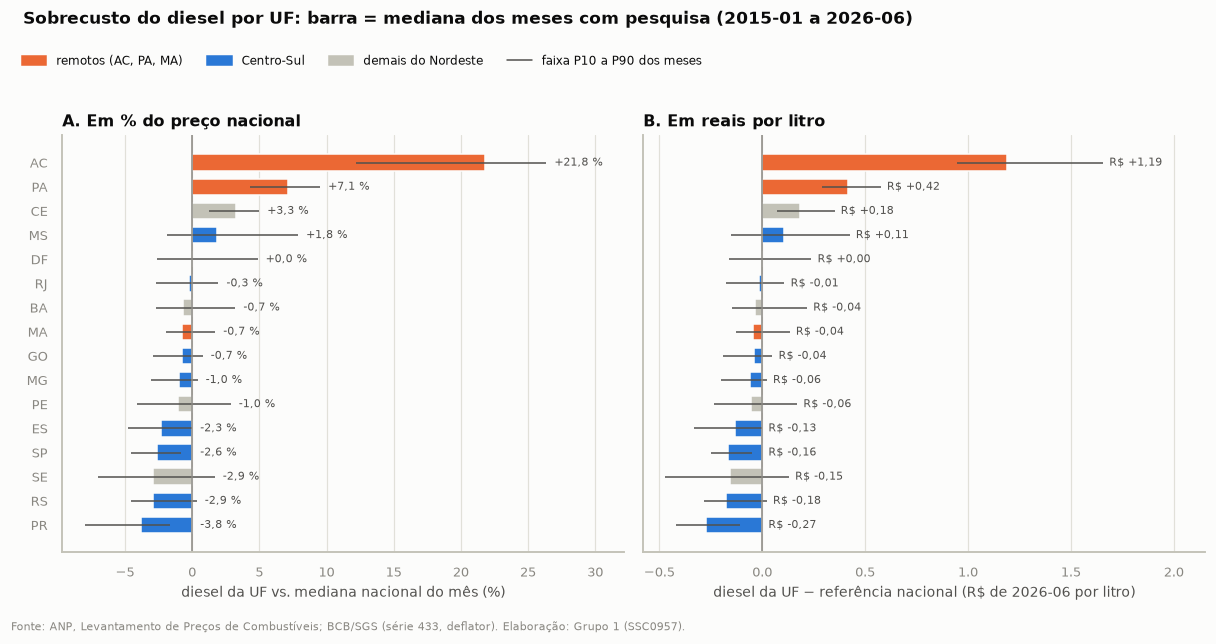

,sobrecusto_pct_mediano,sobrecusto_rs_mediano
sigla_uf,,
"remotos (AC, PA, MA)",7.14,0.42
Centro-Sul,-1.39,-0.09
demais do Nordeste,0.00,0.00


,grupo,pct_mediana,rs_mediana,meses
sigla_uf,,,,
AC,"remotos (AC, PA, MA)",21.82,1.19,83
PA,"remotos (AC, PA, MA)",7.14,0.42,105
CE,demais do Nordeste,3.26,0.18,105
MS,Centro-Sul,1.83,0.11,105
DF,Centro-Sul,0.00,0.00,105
RJ,Centro-Sul,-0.26,-0.01,105


In [8]:
ref_nacional = fato["comb_preco_diesel"] / (1 + fato["comb_diesel_vs_br_pct"] / 100)
fato["diesel_premio_rs"] = fato["comb_preco_diesel"] - ref_nacional
fato["diesel_premio_rs_real"] = fato["diesel_premio_rs"] * fato["deflator"]

obs = fato[fato["comb_observado_liquidos"]]
resumo_uf = obs.groupby("sigla_uf").agg(
    pct_mediana=("comb_diesel_vs_br_pct", "median"),
    pct_p10=("comb_diesel_vs_br_pct", lambda s: s.quantile(0.1)),
    pct_p90=("comb_diesel_vs_br_pct", lambda s: s.quantile(0.9)),
    rs_mediana=("diesel_premio_rs_real", "median"),
    rs_p10=("diesel_premio_rs_real", lambda s: s.quantile(0.1)),
    rs_p90=("diesel_premio_rs_real", lambda s: s.quantile(0.9)),
    meses=("comb_diesel_vs_br_pct", "size"),
).sort_values("pct_mediana")
resumo_uf["grupo"] = resumo_uf.index.map(GRUPO)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.0), sharey=True)
y = np.arange(len(resumo_uf))
cores = [CORES_GRUPO[g] for g in resumo_uf["grupo"]]
for ax, pre, rot, fmt in [(a1, "pct", "diesel da UF vs. mediana nacional do mês (%)", "{:+.1f} %"),
                          (a2, "rs", "diesel da UF − referência nacional (R$ de 2026-06 por litro)", "R$ {:+.2f}")]:
    ax.barh(y, resumo_uf[f"{pre}_mediana"], color=cores, height=0.68, edgecolor=FUNDO, linewidth=1)
    ax.hlines(y, resumo_uf[f"{pre}_p10"], resumo_uf[f"{pre}_p90"], color=TINTA_2, linewidth=1)
    ax.axvline(0, color=TINTA_3, linewidth=1)
    for yi, (v, hi) in enumerate(zip(resumo_uf[f"{pre}_mediana"], resumo_uf[f"{pre}_p90"])):
        ax.text(max(v, hi, 0) + (0.6 if pre == "pct" else 0.03), yi, fmt.format(v).replace(".", ","),
                va="center", fontsize=7.5, color=TINTA_2)
    ax.set_xlabel(rot)
    ax.grid(axis="y", visible=False)
a1.set_yticks(y, resumo_uf.index)
a1.set_xlim(right=resumo_uf["pct_p90"].max() * 1.22)
a2.set_xlim(right=resumo_uf["rs_p90"].max() * 1.3)
a1.set_title("A. Em % do preço nacional")
a2.set_title("B. Em reais por litro")
fig.legend(handles=[Patch(color=c, label=g) for g, c in CORES_GRUPO.items()] +
           [Line2D([], [], color=TINTA_2, linewidth=1, label="faixa P10 a P90 dos meses")],
           loc="upper left", ncol=4, bbox_to_anchor=(0.0, 1.04), fontsize=8)
fig.suptitle("Sobrecusto do diesel por UF: barra = mediana dos meses com pesquisa (2015-01 a 2026-06)",
             x=0.01, ha="left", fontweight="bold", fontsize=11, y=1.1)
plt.tight_layout()
finalizar(fig, "fig_12_02_ranking_sobrecusto_diesel_uf", "comb", "macro")
plt.show()

por_grupo = obs.groupby(obs["sigla_uf"].map(GRUPO)).agg(
    sobrecusto_pct_mediano=("comb_diesel_vs_br_pct", "median"),
    sobrecusto_rs_mediano=("diesel_premio_rs_real", "median"),
).loc[list(CORES_GRUPO)]
display(por_grupo.round(2))
display(resumo_uf[["grupo", "pct_mediana", "rs_mediana", "meses"]].sort_values("pct_mediana", ascending=False)
        .round(2).head(6))

**Leitura (`fig_12_02`), a resposta à pergunta 1:** o sobrecusto é **forte no Norte e quase nulo no Nordeste**.

- **AC: +21,8 %**, ou **R\$ 1,19 por litro** a mais que a referência nacional (em R$ de 2026-06), de longe o maior.
- **PA: +7,1 %** (R\$ 0,42/L). **CE: +3,3 %** (R\$ 0,18/L).
- **O resto do Nordeste paga o preço nacional ou menos:** BA, MA e PE entre −1,0 % e −0,7 %, SE −2,9 %. **O MA, que o
  plano agrupa como remoto, paga o diesel da média nacional**: em custo de combustível, ele não é periferia.
- **O Centro-Sul é o mais barato,** com mediana de −1,4 %; o PR fica em −3,8 % (R\$ −0,27/L). Do PR ao AC, a
  diferença é de ~25 p.p., ou ~R\$ 1,46 por litro.

Por grupo da H1, os remotos têm sobrecusto mediano de +7,1 % (R\$ 0,42/L), mas esse número esconde que o grupo junta
uma UF muito cara (AC), uma moderada (PA) e uma na média (MA).

### 2.2 O sobrecusto é um percentual ou um valor fixo por litro?

Se o sobrecusto de uma UF longe das refinarias for, sobretudo, **frete**, ele deveria se comportar como um valor
fixo em reais por litro, e não como um percentual do preço. Um valor fixo tem uma assinatura: quando o diesel
nacional dispara, o sobrecusto **em %** encolhe, porque o mesmo valor em reais é dividido por um preço maior.

figura salva: outputs/figuras/eda/fig_12_05_sobrecusto_percentual_vs_reais.png


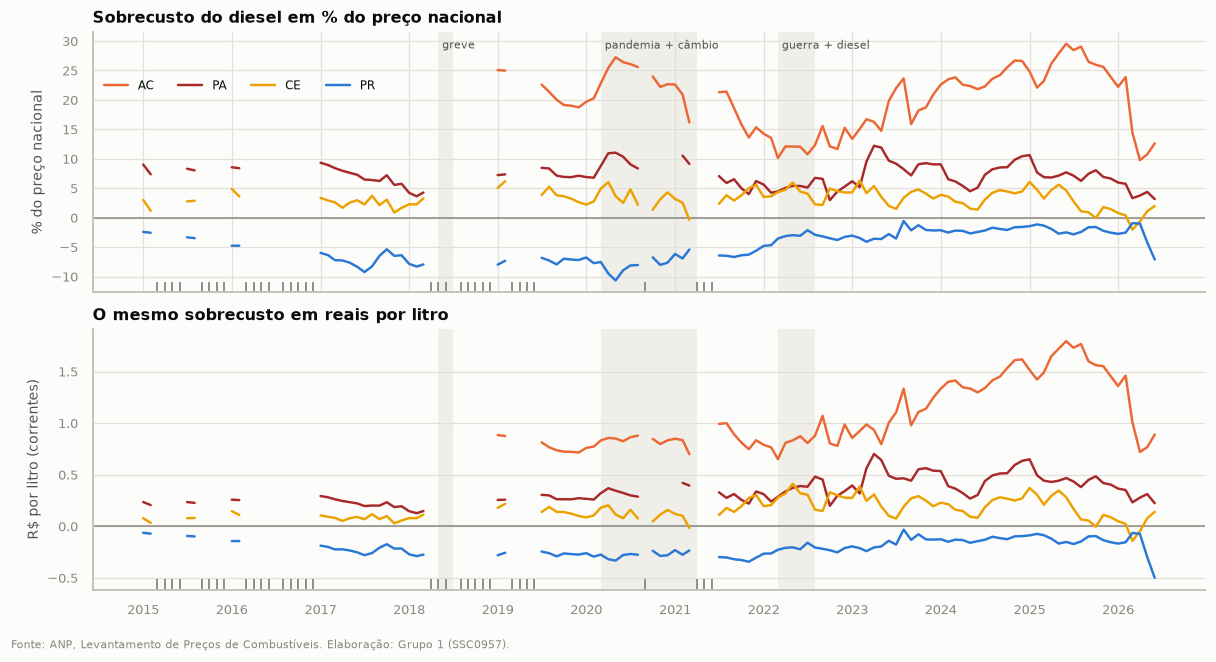

AC 2018-05 a 2021-06: sobrecusto mediano 22.6 % = R$ 0.82/L (correntes), com o diesel nacional em R$ 3.60
AC 2021-07 a 2022-12: sobrecusto mediano 13.6 % = R$ 0.82/L (correntes), com o diesel nacional em R$ 6.44
AC 2023-01 a 2025-12: sobrecusto mediano 23.4 % = R$ 1.41/L (correntes), com o diesel nacional em R$ 6.02

UFs com sobrecusto mediano > 2 % (CE, PA, AC): correlação entre a variação do diesel nacional no mês e a variação do sobrecusto % no mês = -0.33 (n = 264)


In [9]:
UF_PREMIO = {"AC": CORES_GRUPO[G_REM], "PA": "#a8292a", "CE": "#eda100", "PR": CORES_GRUPO[G_CS]}
pct = fato.pivot(index="data", columns="sigla_uf", values="comb_diesel_vs_br_pct")
rs = fato.pivot(index="data", columns="sigla_uf", values="diesel_premio_rs")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.8), sharex=True)
for ax in (a1, a2):
    marcar_eventos(ax, rotulos=ax is a1)
    ax.axhline(0, color=TINTA_3, linewidth=1)
    ax.vlines(sem_datas, 0, 0.04, transform=ax.get_xaxis_transform(), color=TINTA_3, linewidth=1.2)
for uf, cor in UF_PREMIO.items():
    a1.plot(pct.index, pct[uf], color=cor, linewidth=1.6, label=uf)
    a2.plot(rs.index, rs[uf], color=cor, linewidth=1.6)
a1.set_ylabel("% do preço nacional")
a1.set_title("Sobrecusto do diesel em % do preço nacional")
a1.legend(loc="upper left", bbox_to_anchor=(0.0, 0.86), ncol=4, fontsize=8)
a2.set_ylabel("R$ por litro (correntes)")
a2.set_title("O mesmo sobrecusto em reais por litro")
eixo_tempo(a2)
plt.tight_layout()
finalizar(fig, "fig_12_05_sobrecusto_percentual_vs_reais", "comb")
plt.show()

ac = fato[fato["sigla_uf"] == "AC"].set_index("ano_mes")
for a, b in [("2018-05", "2021-06"), ("2021-07", "2022-12"), ("2023-01", "2025-12")]:
    t = ac.loc[a:b]
    print(f"AC {a} a {b}: sobrecusto mediano {t['comb_diesel_vs_br_pct'].median():.1f} % = "
          f"R$ {t['diesel_premio_rs'].median():.2f}/L (correntes), com o diesel nacional em R$ {(t['comb_preco_diesel'] - t['diesel_premio_rs']).median():.2f}")

# Teste: o sobrecusto % cai quando o diesel nacional sobe? (variações mensais, painel, só UFs com sobrecusto > 2 %)
caros = resumo_uf.index[resumo_uf["pct_mediana"] > 2].tolist()
d = fato[fato["sigla_uf"].isin(caros)].copy()
d["d_pct"] = d.groupby("sigla_uf")["comb_diesel_vs_br_pct"].diff()
d["var_ref"] = d["ano_mes"].map(fato.assign(r=ref_nacional).groupby("ano_mes")["r"].median().pct_change(fill_method=None) * 100)
par = d[["var_ref", "d_pct"]].dropna()
r = stats.spearmanr(par["var_ref"], par["d_pct"])
print(f"\nUFs com sobrecusto mediano > 2 % ({', '.join(caros)}): correlação entre a variação do diesel nacional no mês "
      f"e a variação do sobrecusto % no mês = {r.statistic:+.2f} (n = {len(par)})")

**Leitura (`fig_12_05`):** até 2022, o sobrecusto do AC se comportou como um **valor fixo por litro**, e não como um
percentual.

- **De 2018-05 a 2021-06:** 22,6 % = R\$ 0,82/L, com o diesel nacional em R\$ 3,60.
- **De 2021-07 a 2022-12:** **13,6 %**, mas os mesmos **R\$ 0,82/L**, com o diesel nacional em R\$ 6,44.
- **De 2023 a 2025:** o valor em reais sobe para R\$ 1,41/L (23,4 %), chega perto de R\$ 1,80 em 2025 e cai em 2026.
  A tabela não permite saber por quê.

O teste confirma a assinatura do valor fixo. Nas UFs caras (AC, PA, CE), quando o diesel nacional sobe no mês, o
sobrecusto em % cai: ρ = −0,33, com 264 UF-meses.

**Implicação para a H1.** A intuição da H1 é que a periferia sofre mais nos choques do diesel. Em 2022, a periferia
mais cara, o AC, teve o **menor** aumento percentual do diesel. A mesma alta em reais, sobre uma base maior, vira um
percentual menor.

### 2.3 As caudas da variação do diesel

Quais foram os meses de movimento extremo do diesel? Como a variação é quase toda nacional (Seção 0.2), olhamos a
mediana das UFs, um ponto por mês.

In [10]:
vd = fato.groupby("ano_mes")["comb_var_mm_diesel"].median().dropna()
p10, p90 = vd.quantile([0.1, 0.9])
print(f"variação mensal do diesel (mediana das UFs), {len(vd)} meses com dado: "
      f"P10 = {p10:+.1f} %, mediana = {vd.median():+.1f} %, P90 = {p90:+.1f} %")
print(f"assimetria {stats.skew(vd):.2f} · {(vd > 0).mean() * 100:.0f} % dos meses com alta · "
      f"alta média {vd[vd > 0].mean():+.1f} % · queda média {vd[vd < 0].mean():+.1f} %")
ext = pd.concat([vd.nlargest(6), vd.nsmallest(6)]).to_frame("diesel no mês (%)")
ext["alimentos no mês, mesmo mês (%)"] = fato.groupby("ano_mes")[ALVO].median().reindex(ext.index)
ext["alimentos no mês seguinte (%)"] = fato.groupby("ano_mes")[ALVO].median().shift(-1).reindex(ext.index)
display(ext.round(2))

variação mensal do diesel (mediana das UFs), 95 meses com dado: P10 = -3.3 %, mediana = +0.3 %, P90 = +5.8 %
assimetria 0.97 · 61 % dos meses com alta · alta média +2.8 % · queda média -2.3 %


,diesel no mês (%),"alimentos no mês, mesmo mês (%)",alimentos no mês seguinte (%)
ano_mes,,,
2023-08,14.22,-0.75,-0.69
2026-03,14.13,1.49,1.40
2022-03,12.69,2.23,2.04
2023-09,7.88,-0.69,0.21
2021-03,7.42,0.24,0.44
2021-10,6.76,1.33,0.12
2020-05,-7.77,0.24,0.28
2020-04,-7.58,1.66,0.24
2023-05,-6.92,-0.10,-0.69


**Leitura:** a variação mensal do diesel é **assimétrica**. 61 % dos meses são de alta, a alta média (+2,8 %) é maior
que a queda média (−2,3 %), e a cauda de cima é mais longa (P90 de +5,8 % contra P10 de −3,3 %; assimetria de 0,97).

Os meses extremos do diesel **não são meses extremos da comida**:

- **2023-08:** o diesel subiu 14,2 % e a comida caiu 0,75 % no mesmo mês.
- **2022-03:** o diesel subiu 12,7 % e a comida subiu 2,23 %, mas esse mês também é o do início da guerra, do IGP-M e
  dos grãos.
- **2020-04 e 2020-05:** as maiores quedas do diesel (−7,6 % e −7,8 %), no começo da pandemia, não derrubaram a
  comida.

---
## 3. Casos especiais & quebras estruturais

> **Objetivo:** responder às **perguntas 2 e 3**, com os dois choques logísticos do período: a greve dos
> caminhoneiros (maio de 2018) e o choque do petróleo de 2022.

### 3.1 A greve de 2018: a tabela não vê o diesel, mas vê a comida

A ANP não tem pesquisa de **2018-04 a 2018-06**. O diesel durante a greve é invisível. Mas a greve foi, antes de
tudo, um choque de **abastecimento**, e esse aparece na inflação de alimentos de maio e junho. Medimos, por UF, o
**excesso** sobre o típico: a variação composta de maio e junho de 2018 menos a média dos maio-junho de todos os
outros anos daquela UF.

In [11]:
def composto(s):
    return ((1 + s / 100).prod() - 1) * 100


ITENS_GREVE = {ALVO: "alimentação (grupo)", "ipca_var_batata_inglesa": "batata-inglesa",
               "ipca_var_leite_longa_vida": "leite longa vida", "ipca_var_hortalicas": "hortaliças",
               "ipca_var_carnes": "carnes", "ipca_var_frango_inteiro": "frango inteiro"}
mj = fato[fato["mes_cal"].isin([5, 6])]
linhas = []
for uf in ORDEM_UF:
    sub = mj[mj["sigla_uf"] == uf]
    for col, nome in ITENS_GREVE.items():
        por_ano = sub.groupby(sub["ano_mes"].dt.year)[col].apply(composto)
        linhas.append({"uf": uf, "item": nome, "2018": por_ano.get(2018, np.nan),
                       "típico (outros anos)": por_ano.drop(2018, errors="ignore").mean()})
greve = pd.DataFrame(linhas)
greve["excesso (p.p.)"] = greve["2018"] - greve["típico (outros anos)"]
exc = greve[greve["item"] == "alimentação (grupo)"].set_index("uf")["excesso (p.p.)"]

itens = greve.groupby("item")[["2018", "típico (outros anos)", "excesso (p.p.)"]].median().loc[list(ITENS_GREVE.values())]
print("maio + junho de 2018 contra o típico, mediana das UFs (%):")
display(itens.round(1))
print("excesso da alimentação por grupo de UFs (média, p.p.):",
      {g: round(exc[[u for u in exc.index if GRUPO[u] == g]].mean(), 2) for g in CORES_GRUPO})
mw = stats.mannwhitneyu(exc[REMOTOS], exc[CENTRO_SUL], alternative="two-sided")
print(f"remotos × Centro-Sul (Mann-Whitney, 3 × 9 UFs): p = {mw.pvalue:.2f}")

w = fato.pivot(index="ano_mes", columns="sigla_uf", values="comb_preco_diesel")
antes_depois = (w.loc["2018-07"] / w.loc["2018-03"] - 1) * 100
print(f"\ndiesel de 2018-03 (antes) para 2018-07 (depois), {antes_depois.notna().sum()} UFs com os dois meses: "
      f"mediana {antes_depois.median():+.1f} % (de {antes_depois.min():+.1f} % a {antes_depois.max():+.1f} %)")

maio + junho de 2018 contra o típico, mediana das UFs (%):


,2018,típico (outros anos),excesso (p.p.)
item,,,
alimentação (grupo),2.2,0.5,1.7
batata-inglesa,36.4,9.4,23.8
leite longa vida,13.5,5.3,8.7
hortaliças,4.1,-0.8,6.3
carnes,2.8,0.2,2.5
frango inteiro,6.2,0.4,4.6


excesso da alimentação por grupo de UFs (média, p.p.): {'remotos (AC, PA, MA)': np.float64(1.47), 'Centro-Sul': np.float64(1.91), 'demais do Nordeste': np.float64(1.34)}
remotos × Centro-Sul (Mann-Whitney, 3 × 9 UFs): p = 0.37

diesel de 2018-03 (antes) para 2018-07 (depois), 13 UFs com os dois meses: mediana -0.3 % (de -5.8 % a +2.3 %)


**Leitura (`fig_12_03`, painel B), primeira parte da pergunta 3:**

- **A greve aparece, e é um choque de perecíveis.** Em maio e junho de 2018, a alimentação subiu 2,2 % (mediana das
  UFs), contra 0,5 % num maio-junho típico: **1,7 p.p. de excesso**. Os itens dizem o tipo de choque: batata-inglesa
  +36 % (contra 9 % típicos), leite longa vida +13,5 %, hortaliças +4,1 % (contra −0,8 %), frango inteiro +6,2 %. É o
  que falta quando o caminhão não chega: o que estraga ou não se estoca.
- **Não foi maior nas UFs remotas.** O excesso médio foi de 1,47 p.p. nos remotos, 1,91 p.p. no Centro-Sul e 1,34 p.p.
  no resto do Nordeste (Mann-Whitney p = 0,37). O maior foi no PR (2,8 p.p.) e o menor no PA (0,7 p.p.).
- **O diesel não mudou de patamar.** De 2018-03 a 2018-07 a variação mediana foi de −0,3 %, coerente com o acordo que
  encerrou a greve e reduziu o preço do diesel. O choque foi de **abastecimento**, não de preço do combustível, e a
  ANP, de qualquer modo, não mediu aqueles meses.

### 3.2 O choque de 2022: subida, pico e devolução, UF por UF

Na janela contínua, o diesel sobe de 2021-07 até o pico de 2022-07 e depois cai. Três perguntas:

- **A alta foi maior nas UFs remotas?** (diesel de 2021-07 a 2022-07, por UF)
- **A queda devolveu a alta?** Se a queda de 2022-07 a 2023-07 for menor que a alta, sobra uma parte do choque
  no preço: é a **histerese** da pergunta 2.
- **A comida subiu mais onde o diesel subiu mais?**

,alta (%),devolvido (% da alta),alimentos 2021-08 a 2022-12 (%)
grupo,,,
"remotos (AC, PA, MA)",56.8,85.0,15.0
Centro-Sul,62.8,86.6,16.9
demais do Nordeste,59.4,92.6,16.0


alta do diesel × alta dos alimentos entre UFs: Spearman +0.08 (p = 0.77, n = 16)
devolução da alta em 12 meses: mediana 86 % (de 82 % a 101 %)
pico do diesel (mediana das UFs): 2022-07 · pico da alimentação em 12 meses na mesma fase: 2022-07 (14.2 %)
figura salva: outputs/figuras/eda/fig_12_03_choques_logistica_2018_2022.png


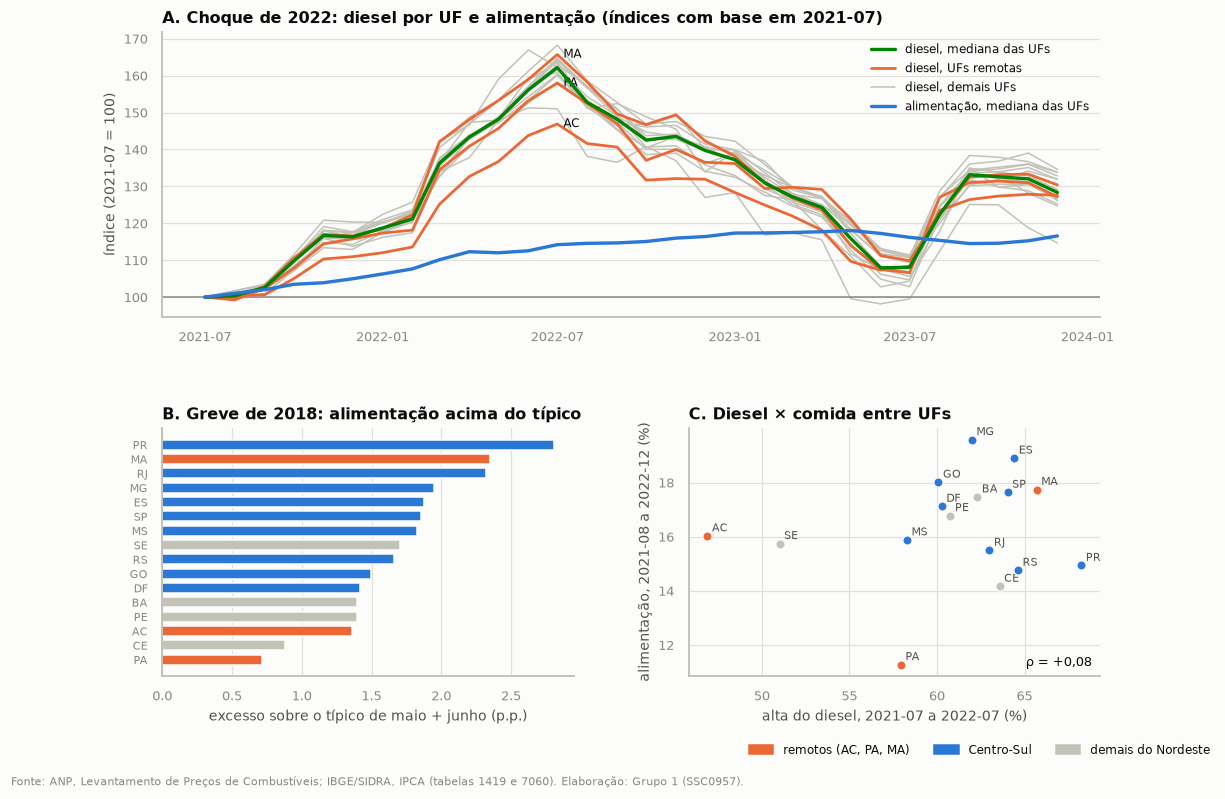

In [12]:
w = fato.pivot(index="ano_mes", columns="sigla_uf", values="comb_preco_diesel")
choque = pd.DataFrame({
    "alta (R$/L)": w.loc["2022-07"] - w.loc["2021-07"],
    "alta (%)": (w.loc["2022-07"] / w.loc["2021-07"] - 1) * 100,
    "queda (R$/L)": w.loc["2022-07"] - w.loc["2023-07"],
})
choque["devolvido (% da alta)"] = choque["queda (R$/L)"] / choque["alta (R$/L)"] * 100
alim = fato.pivot(index="ano_mes", columns="sigla_uf", values=ALVO)
choque["alimentos 2021-08 a 2022-12 (%)"] = alim.loc["2021-08":"2022-12"].apply(composto)
choque["grupo"] = choque.index.map(GRUPO)
display(choque.groupby("grupo")[["alta (%)", "devolvido (% da alta)", "alimentos 2021-08 a 2022-12 (%)"]]
        .mean().loc[list(CORES_GRUPO)].round(1))
r_choque = stats.spearmanr(choque["alta (%)"], choque["alimentos 2021-08 a 2022-12 (%)"])
print(f"alta do diesel × alta dos alimentos entre UFs: Spearman {r_choque.statistic:+.2f} (p = {r_choque.pvalue:.2f}, n = 16)")
print(f"devolução da alta em 12 meses: mediana {choque['devolvido (% da alta)'].median():.0f} % "
      f"(de {choque['devolvido (% da alta)'].min():.0f} % a {choque['devolvido (% da alta)'].max():.0f} %)")

# Linha do tempo do choque: índices com base em 2021-07 (mesma unidade, um só eixo).
jan = slice("2021-07", "2023-12")
idx_d = (w.loc[jan] / w.loc["2021-07"] * 100)
idx_a = (1 + alim.loc["2021-08":"2023-12"] / 100).cumprod() * 100
idx_a.loc[pd.Period("2021-07", "M")] = 100
idx_a = idx_a.sort_index()
med_a = idx_a.median(axis=1)
pico_d = idx_d.median(axis=1).idxmax()
acum12_a = fato.groupby("ano_mes")[ACUM12].median().loc["2022-01":"2023-06"]
print(f"pico do diesel (mediana das UFs): {pico_d} · pico da alimentação em 12 meses na mesma fase: "
      f"{acum12_a.idxmax()} ({acum12_a.max():.1f} %)")

fig = plt.figure(figsize=(11, 7.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1], hspace=0.42, wspace=0.28)
ax = fig.add_subplot(gs[0, :])
for uf in idx_d.columns:
    ax.plot(idx_d.index.to_timestamp(), idx_d[uf], color=CORES_GRUPO[GRUPO[uf]] if uf in REMOTOS else NEUTRO,
            linewidth=1.8 if uf in REMOTOS else 1, zorder=3 if uf in REMOTOS else 2)
ax.plot(idx_d.index.to_timestamp(), idx_d.median(axis=1), color=CORES["comb"], linewidth=2.2, zorder=4)
ax.plot(med_a.index.to_timestamp(), med_a, color=CORES["ipca"], linewidth=2.2, zorder=4)
ax.axhline(100, color=TINTA_3, linewidth=1)
for uf in REMOTOS:
    ax.annotate(uf, (pico_d.to_timestamp(), idx_d.loc[pico_d, uf]), xytext=(4, 0), textcoords="offset points",
                fontsize=8, color=TINTA, va="center")
ax.set_ylabel("índice (2021-07 = 100)")
ax.set_title("A. Choque de 2022: diesel por UF e alimentação (índices com base em 2021-07)")
ax.legend(handles=[Line2D([], [], color=CORES["comb"], linewidth=2.2, label="diesel, mediana das UFs"),
                   Line2D([], [], color=CORES_GRUPO[G_REM], linewidth=1.8, label="diesel, UFs remotas"),
                   Line2D([], [], color=NEUTRO, linewidth=1, label="diesel, demais UFs"),
                   Line2D([], [], color=CORES["ipca"], linewidth=2.2, label="alimentação, mediana das UFs")],
          loc="upper right", fontsize=8, ncol=1)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(axis="x", visible=False)

ax = fig.add_subplot(gs[1, 0])
exc_ord = exc.sort_values()
ax.barh(exc_ord.index, exc_ord.values, color=[CORES_GRUPO[GRUPO[u]] for u in exc_ord.index], height=0.7,
        edgecolor=FUNDO)
ax.axvline(0, color=TINTA_3, linewidth=1)
ax.set_xlabel("excesso sobre o típico de maio + junho (p.p.)")
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)
ax.set_title("B. Greve de 2018: alimentação acima do típico")

ax = fig.add_subplot(gs[1, 1])
for uf, lin in choque.iterrows():
    ax.scatter(lin["alta (%)"], lin["alimentos 2021-08 a 2022-12 (%)"], s=36, color=CORES_GRUPO[lin["grupo"]],
               edgecolor=FUNDO, linewidth=0.8, zorder=3)
    ax.annotate(uf, (lin["alta (%)"], lin["alimentos 2021-08 a 2022-12 (%)"]), xytext=(3, 3),
                textcoords="offset points", fontsize=7.5, color=TINTA_2)
ax.set_xlabel("alta do diesel, 2021-07 a 2022-07 (%)")
ax.set_ylabel("alimentação, 2021-08 a 2022-12 (%)")
ax.set_title("C. Diesel × comida entre UFs")
ax.text(0.98, 0.04, f"ρ = {r_choque.statistic:+.2f}".replace(".", ","), transform=ax.transAxes, ha="right",
        fontsize=8.5, color=TINTA)
fig.legend(handles=[Patch(color=c, label=g) for g, c in CORES_GRUPO.items()], loc="lower right",
           bbox_to_anchor=(1.0, 0.0), ncol=3, fontsize=8)
finalizar(fig, "fig_12_03_choques_logistica_2018_2022", "comb", "ipca")
plt.show()

**Leitura (`fig_12_03`, painéis A e C), pergunta 3 (2022) e primeira parte da pergunta 2:**

- **O choque foi nacional e chegou menos à periferia em %.** De 2021-07 a 2022-07 o diesel subiu 63 % no Centro-Sul,
  59 % no resto do Nordeste e **57 % nas remotas**. O AC teve a menor alta de todas (47 %), como prevê o sobrecusto
  fixo da Seção 2.2.
- **A comida subiu muito menos que o diesel** (painel A): ~14 % contra ~62 % no pico. O pico da alimentação em 12
  meses (14,2 %) coincide com o pico do diesel (2022-07). A coincidência de datas é o que gera a correlação de 0,72 da
  Seção 1.1.
- **Diesel × comida entre UFs: nada** (painel C, ρ = +0,08, p = 0,77). A UF onde o diesel subiu mais não teve mais
  inflação de alimentos. O PA teve a menor inflação de alimentos (11 %) com uma alta do diesel na média.
- **Histerese no próprio diesel: parcial e igual em todo lugar.** Doze meses depois do pico, as UFs tinham devolvido
  de 82 % a 101 % da alta (mediana de 86 %). Sobrou ~14 % do choque no preço, sem diferença entre grupos (remotos
  85 %, Centro-Sul 87 %). Logo depois veio uma nova alta, em 2023-08 (+14 %).

### 3.3 Histerese do diesel para a comida

A Seção 3.2 olhou o próprio preço do diesel. Agora, a transmissão para a comida: o efeito de uma **alta** do diesel
sobre a inflação de alimentos é maior que o de uma **queda** do mesmo tamanho? Separamos a variação mensal do diesel
nacional (média das UFs) em parte positiva e parte negativa e regredimos a inflação de alimentos (sem a
sazonalidade) nas duas, com defasagens de 0 a 3 meses. É feito só na janela contínua, onde as defasagens existem.
Erro-padrão de Newey-West (3 lags).

In [13]:
# Alvo sem a sazonalidade da UF (mesma "anomalia" do notebook 14) e séries nacionais (média das UFs).
fato["alvo_anom"] = fato[ALVO] - fato.groupby(["sigla_uf", "mes_cal"])[ALVO].transform("mean")
n_d = fato.groupby("ano_mes")["comb_var_mm_diesel"].mean()
n_y = fato.groupby("ano_mes")["alvo_anom"].mean()
H = pd.DataFrame({"y": n_y, "alta": n_d.clip(lower=0), "queda": n_d.clip(upper=0)})
for k in range(1, 4):
    H[f"alta_l{k}"] = H["alta"].shift(k)
    H[f"queda_l{k}"] = H["queda"].shift(k)
H = H.loc[JANELA[0] + 1:JANELA[1]].dropna()
X = sm.add_constant(H.drop(columns="y"))
fit = sm.OLS(H["y"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
c_alta = [c for c in X.columns if c.startswith("alta")]
c_queda = [c for c in X.columns if c.startswith("queda")]
b_alta, b_queda = fit.params[c_alta].sum(), fit.params[c_queda].sum()
R = np.zeros((1, len(X.columns)))
R[0, [list(X.columns).index(c) for c in c_alta]] = 1
R[0, [list(X.columns).index(c) for c in c_queda]] = -1
teste = fit.t_test(R)
p_alta = fit.t_test(np.where(np.isin(X.columns, c_alta), 1, 0)[None, :]).pvalue
p_queda = fit.t_test(np.where(np.isin(X.columns, c_queda), 1, 0)[None, :]).pvalue
print(f"{len(H)} meses ({H.index[0]} a {H.index[-1]}) · {(H['alta'] > 0).sum()} meses de alta e {(H['queda'] < 0).sum()} de queda do diesel")
print(f"efeito acumulado (0 a 3 meses) de +1 % no diesel: {b_alta:+.3f} p.p. na comida (p = {float(p_alta):.2f})")
print(f"efeito acumulado (0 a 3 meses) de −1 % no diesel: {-b_queda:+.3f} p.p. na comida (p = {float(p_queda):.2f})")
print(f"diferença alta − queda: p = {float(teste.pvalue):.2f} · R² = {fit.rsquared:.2f}")

56 meses (2021-11 a 2026-06) · 28 meses de alta e 28 de queda do diesel
efeito acumulado (0 a 3 meses) de +1 % no diesel: +0.083 p.p. na comida (p = 0.04)
efeito acumulado (0 a 3 meses) de −1 % no diesel: -0.154 p.p. na comida (p = 0.01)
diferença alta − queda: p = 0.41 · R² = 0.34


**Leitura, segunda parte da pergunta 2:** **não há sinal de histerese do diesel para a comida.**

- **Alta:** +1 % de diesel leva a +0,08 p.p. na comida em até 3 meses (p = 0,04).
- **Queda:** −1 % de diesel leva a −0,15 p.p. (p = 0,01).
- **Diferença:** p = 0,41. As estimativas pontuais vão até na direção **oposta** à histerese (a queda transmite mais
  que a alta).

Duas cautelas:

1. São 56 meses e um choque dominante.
2. As grandes quedas do diesel em 2023 coincidiram com a deflação de alimentos daquele ano, que teve outras causas (o
   notebook 09 mostra o acumulado em 12 meses perto de zero no fim de 2023). A regressão não separa as duas coisas.

A assimetria que o notebook 14 encontrou está no IGP-M e no dólar, não no diesel.

---
## 4. Representatividade espaço-temporal por propósito: o teste da H1

> **Objetivo:** testar formalmente a H1 com os dados que temos, e dizer com clareza o que esses dados podem e não
> podem responder.

### 4.1 Quem está na amostra

A Proposta cita **AM e AP** como exemplos de estados distantes dos polos produtores. Nenhum dos dois está no IPCA.

In [14]:
TODAS = {"Norte": ["AC", "AM", "AP", "PA", "RO", "RR", "TO"], "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
         "Centro-Oeste": ["DF", "GO", "MS", "MT"], "Sudeste": ["ES", "MG", "RJ", "SP"], "Sul": ["PR", "RS", "SC"]}
na_janela = fato[fato["ano_mes"].between(*JANELA)]
linhas = []
for reg, lista in TODAS.items():
    dentro = [u for u in lista if u in ORDEM_UF]
    linhas.append({"região": reg, "UFs no IPCA (alvo)": ", ".join(dentro),
                   "fora do IPCA": ", ".join(u for u in lista if u not in ORDEM_UF),
                   "meses com alvo e diesel, por UF": " / ".join(
                       f"{u}: {int(fato.loc[fato['sigla_uf'] == u, 'comb_observado_liquidos'].sum())}" for u in dentro)})
display(pd.DataFrame(linhas).set_index("região"))
print(f"na janela contínua ({JANELA[0]} a {JANELA[1]}): {na_janela['sigla_uf'].nunique()} UFs × "
      f"{na_janela['ano_mes'].nunique()} meses, sem buraco")

,UFs no IPCA (alvo),fora do IPCA,"meses com alvo e diesel, por UF"
região,,,
Norte,"AC, PA","AM, AP, RO, RR, TO",AC: 83 / PA: 105
Nordeste,"BA, CE, MA, PE, SE","AL, PB, PI, RN",BA: 105 / CE: 105 / MA: 83 / PE: 105 / SE: 83
Centro-Oeste,"DF, GO, MS",MT,DF: 105 / GO: 105 / MS: 105
Sudeste,"ES, MG, RJ, SP",,ES: 105 / MG: 105 / RJ: 105 / SP: 105
Sul,"PR, RS",SC,PR: 105 / RS: 105


na janela contínua (2021-07 a 2026-06): 16 UFs × 60 meses, sem buraco


**Leitura:** a amostra é fraca justamente onde a H1 é mais forte.

- **Dos 7 estados do Norte, só 2 estão no IPCA** (AC e PA). AM e AP, os exemplos da própria Proposta, ficam de fora,
  assim como RO, RR e TO.
- **O AC só entra em 2018-05** e, com os buracos da ANP, tem 83 meses com alvo e diesel. Na janela contínua todas as
  UFs ficam completas (16 × 60), e é ali que o teste é feito.
- **O Centro-Oeste está sem o MT**, o maior produtor de grãos e a origem de boa parte do frete.

### 4.2 O teste: quanto o diesel explica da inflação de alimentos, UF por UF

A H1 diz que, nos estados remotos, o diesel explica **mais de 50 %** da variância do preço dos alimentos. O teste
mais direto, para cada UF, é uma regressão da inflação de alimentos no mês (sem a sazonalidade da UF) na variação do
diesel **da própria UF** no mesmo mês e nos 3 meses anteriores:

$$\text{alimentos}_{t} = a + \sum_{k=0}^{3} b_k \,\Delta\text{diesel}_{t-k} + e_t$$

Medimos duas coisas:

- **R²:** que fração da variância o diesel explica. É a métrica da H1.
- **Sensibilidade** (\(\sum b_k\)): quantos p.p. a comida sobe, em até 3 meses, para cada 1 % de alta do diesel.

Tudo na janela contínua, de 2021-11 em diante (para ter os 3 lags). Em 2025-08, SE não tem diesel comum; os meses que
dependem dele saem de **todas** as UFs, para que todas usem exatamente os mesmos meses. As defasagens vêm de
`adicionar_lags_painel` (o utilitário do grupo). Os intervalos de 90 % são de um **bootstrap em blocos de 6 meses**,
com os mesmos meses sorteados para todas as UFs, o que preserva o fato de as UFs se moverem juntas. Assim, a
diferença entre grupos também ganha um intervalo.

In [15]:
LAGS = [1, 2, 3]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    P = adicionar_lags_painel(fato[["sigla_uf", "ano_mes", "alvo_anom", "comb_var_mm_diesel"]], ["comb_var_mm_diesel"], lags=LAGS)
XCOLS = ["comb_var_mm_diesel"] + [f"comb_var_mm_diesel_lag{k}" for k in LAGS]
P = P[P["ano_mes"].between(*JANELA)]
# O bootstrap sorteia os MESMOS meses para todas as UFs: fica só o mês completo nas 16.
completo = P.dropna(subset=["alvo_anom", *XCOLS]).groupby("ano_mes")["sigla_uf"].nunique()
MESES_H1 = np.array(sorted(completo.index[completo == len(ORDEM_UF)]))
fora = sorted(set(P["ano_mes"]) - set(MESES_H1) - set(pd.period_range(JANELA[0], JANELA[0] + 3, freq="M")))
print(f"meses da janela que saem por faltar diesel em alguma UF: {', '.join(map(str, fora)) or 'nenhum'}")
P = P[P["ano_mes"].isin(MESES_H1)]

# Matrizes por UF, alinhadas pelos mesmos meses (para o bootstrap conjunto).
Y = {u: g.set_index("ano_mes").loc[MESES_H1, "alvo_anom"].to_numpy() for u, g in P.groupby("sigla_uf")}
XM = {u: g.set_index("ano_mes").loc[MESES_H1, XCOLS].to_numpy() for u, g in P.groupby("sigla_uf")}


def ajusta(y, X):
    Xc = np.column_stack([np.ones(len(y)), X])
    coef, *_ = np.linalg.lstsq(Xc, y, rcond=None)
    res = y - Xc @ coef
    return 1 - res.var() / y.var(), coef[1:].sum()


def estatisticas(idx):
    out = {u: ajusta(Y[u][idx], XM[u][idx]) for u in Y}
    r2 = pd.Series({u: v[0] for u, v in out.items()})
    sens = pd.Series({u: v[1] for u, v in out.items()})
    return r2, sens


T, L, B = len(MESES_H1), 6, 2000
rng = np.random.default_rng(12)
base_r2, base_sens = estatisticas(np.arange(T))
boot_r2, boot_sens, boot_dif = [], [], []
for _ in range(B):
    inicios = rng.integers(0, T - L + 1, size=int(np.ceil(T / L)))
    idx = np.concatenate([np.arange(s, s + L) for s in inicios])[:T]
    r2, sens = estatisticas(idx)
    boot_r2.append(r2)
    boot_sens.append(sens)
    boot_dif.append(r2[REMOTOS].mean() - r2[CENTRO_SUL].mean())
boot_r2, boot_sens = pd.DataFrame(boot_r2), pd.DataFrame(boot_sens)

h1 = pd.DataFrame({
    "grupo": pd.Series(GRUPO),
    "R² (%)": base_r2 * 100,
    "R² IC90 inf": boot_r2.quantile(0.05) * 100,
    "R² IC90 sup": boot_r2.quantile(0.95) * 100,
    "sensibilidade (p.p. por 1 %)": base_sens,
    "sens IC90 inf": boot_sens.quantile(0.05),
    "sens IC90 sup": boot_sens.quantile(0.95),
    "sobrecusto do diesel (%)": resumo_uf["pct_mediana"],
}).loc[ORDEM_UF]

# Referência do acaso: R² que 4 regressores sem relação nenhuma dariam com esse n.
r2_acaso = []
for _ in range(2000):
    xs = rng.permutation(T)
    r2_acaso.append(ajusta(Y["SP"], XM["SP"][xs])[0])
R2_ACASO = np.quantile(r2_acaso, 0.95) * 100

dif = base_r2[REMOTOS].mean() - base_r2[CENTRO_SUL].mean()
ic_dif = np.quantile(boot_dif, [0.05, 0.95])
print(f"{T} meses por UF ({MESES_H1[0]} a {MESES_H1[-1]})")
print(f"R² médio: remotos {base_r2[REMOTOS].mean() * 100:.1f} % · Centro-Sul {base_r2[CENTRO_SUL].mean() * 100:.1f} % · "
      f"diferença {dif * 100:+.1f} p.p. (IC90 de {ic_dif[0] * 100:+.1f} a {ic_dif[1] * 100:+.1f})")
print(f"maior R² entre as 16 UFs: {base_r2.max() * 100:.1f} % ({base_r2.idxmax()}) · limite da H1: 50 % · "
      f"R² que o puro acaso alcança em 5 % das vezes com este n: {R2_ACASO:.1f} %")
r_sens = stats.spearmanr(h1["sobrecusto do diesel (%)"], h1["sensibilidade (p.p. por 1 %)"])
r_r2 = stats.spearmanr(h1["sobrecusto do diesel (%)"], h1["R² (%)"])
print(f"sobrecusto × sensibilidade entre as 16 UFs: Spearman {r_sens.statistic:+.2f} (p = {r_sens.pvalue:.2f}); "
      f"sobrecusto × R²: {r_r2.statistic:+.2f} (p = {r_r2.pvalue:.2f})")
display(h1.round(2))

meses da janela que saem por faltar diesel em alguma UF: 2025-08, 2025-09, 2025-10, 2025-11, 2025-12
51 meses por UF (2021-11 a 2026-06)
R² médio: remotos 20.9 % · Centro-Sul 17.0 % · diferença +3.9 p.p. (IC90 de -12.0 a +14.6)
maior R² entre as 16 UFs: 30.1 % (AC) · limite da H1: 50 % · R² que o puro acaso alcança em 5 % das vezes com este n: 18.2 %
sobrecusto × sensibilidade entre as 16 UFs: Spearman +0.05 (p = 0.85); sobrecusto × R²: -0.02 (p = 0.94)


,grupo,R² (%),R² IC90 inf,R² IC90 sup,sensibilidade (p.p. por 1 %),sens IC90 inf,sens IC90 sup,sobrecusto do diesel (%)
AC,"remotos (AC, PA, MA)",30.06,6.11,68.28,0.14,0.05,0.23,21.82
PA,"remotos (AC, PA, MA)",12.95,6.42,39.43,0.09,0.02,0.18,7.14
BA,demais do Nordeste,19.51,4.70,41.64,0.08,0.02,0.13,-0.67
CE,demais do Nordeste,16.72,7.45,46.73,0.07,0.01,0.12,3.26
MA,"remotos (AC, PA, MA)",19.61,6.75,53.28,0.09,-0.01,0.15,-0.73
PE,demais do Nordeste,6.97,3.50,38.60,0.05,-0.02,0.12,-1.02
SE,demais do Nordeste,10.41,4.52,29.68,0.06,-0.02,0.11,-2.91
DF,Centro-Sul,16.88,8.34,48.72,0.08,0.03,0.13,0.00
GO,Centro-Sul,11.29,6.95,43.54,0.09,0.04,0.16,-0.74
MS,Centro-Sul,12.96,10.17,40.57,0.11,0.02,0.20,1.83


In [16]:
# Mesmo teste com o diesel nacional (mediana das UFs) no lugar do diesel da própria UF.
nac_d = fato.groupby("ano_mes")["comb_var_mm_diesel"].median()
Xn = np.column_stack([nac_d.reindex(MESES_H1 - k).to_numpy() for k in range(0, 4)])
r2_nac = pd.Series({u: ajusta(Y[u], Xn)[0] for u in Y}) * 100
print(f"R² com o diesel da própria UF × com o diesel nacional (média das 16 UFs): "
      f"{base_r2.mean() * 100:.1f} % × {r2_nac.mean():.1f} %")

# A H1 também pode ser lida em nível: UF com diesel mais caro acumula mais inflação de alimentos?
comum = fato[fato["ano_mes"] >= pd.Period("2018-05", "M")]
acum_uf = comum.groupby("sigla_uf")[ALVO].apply(composto)
r_nivel = stats.spearmanr(resumo_uf["pct_mediana"].loc[acum_uf.index], acum_uf)
print(f"sobrecusto mediano do diesel × inflação de alimentos acumulada em 2018-05 a 2026-06 (16 UFs): "
      f"Spearman {r_nivel.statistic:+.2f} (p = {r_nivel.pvalue:.2f})")

R² com o diesel da própria UF × com o diesel nacional (média das 16 UFs): 16.8 % × 16.7 %
sobrecusto mediano do diesel × inflação de alimentos acumulada em 2018-05 a 2026-06 (16 UFs): Spearman -0.11 (p = 0.70)


figura salva: outputs/figuras/eda/fig_12_04_teste_hipotese_h1_dispersao_uf.png


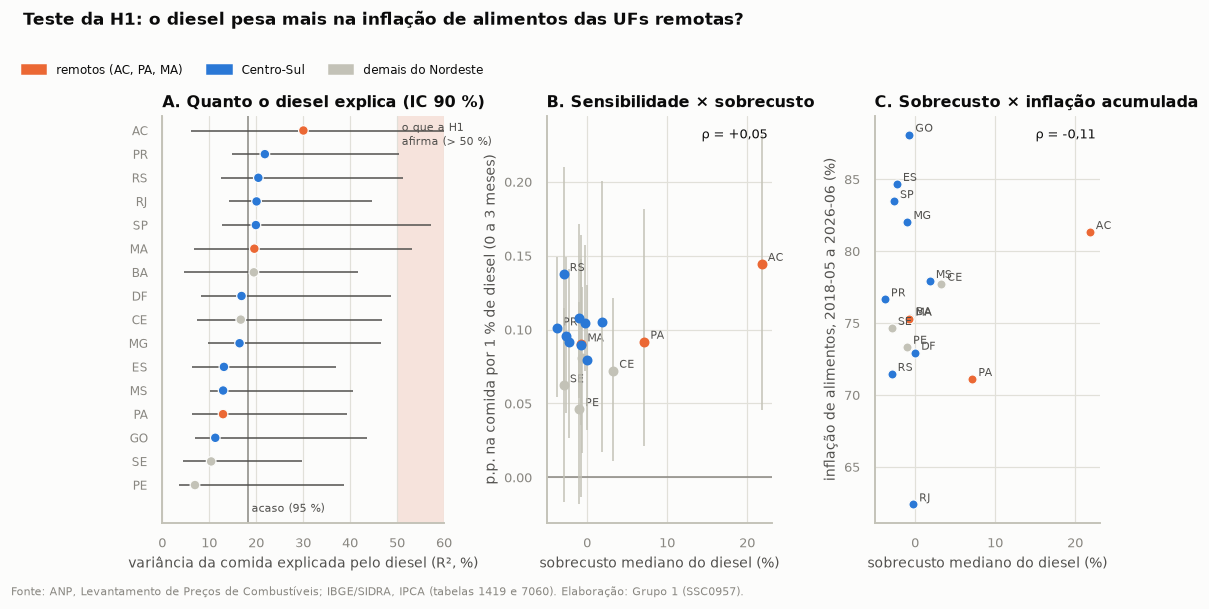

In [17]:
ordem = h1.sort_values("R² (%)").index
fig = plt.figure(figsize=(11, 4.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1, 1], wspace=0.42)

ax = fig.add_subplot(gs[0])
yy = np.arange(len(ordem))
ax.axvspan(50, 100, color="#f6e3dc", linewidth=0, zorder=0)
ax.text(51, len(ordem) - 0.6, "o que a H1\nafirma (> 50 %)", fontsize=7.5, color=TINTA_2, va="top")
ax.axvline(R2_ACASO, color=TINTA_3, linewidth=1)
ax.text(R2_ACASO + 0.8, -1.0, "acaso (95 %)", fontsize=7.5, color=TINTA_2, va="center")
ax.set_ylim(-1.6, len(ordem) - 0.4)
ax.hlines(yy, h1.loc[ordem, "R² IC90 inf"], h1.loc[ordem, "R² IC90 sup"], color=TINTA_2, linewidth=1)
ax.scatter(h1.loc[ordem, "R² (%)"], yy, s=40, color=[CORES_GRUPO[GRUPO[u]] for u in ordem], zorder=3,
           edgecolor=FUNDO, linewidth=0.8)
ax.set_yticks(yy, ordem, fontsize=8)
ax.set_xlim(0, 60)
ax.set_xlabel("variância da comida explicada pelo diesel (R², %)")
ax.grid(axis="y", visible=False)
ax.set_title("A. Quanto o diesel explica (IC 90 %)")

ax = fig.add_subplot(gs[1])
for u in ORDEM_UF:
    ax.errorbar(h1.loc[u, "sobrecusto do diesel (%)"], h1.loc[u, "sensibilidade (p.p. por 1 %)"],
                yerr=[[h1.loc[u, "sensibilidade (p.p. por 1 %)"] - h1.loc[u, "sens IC90 inf"]],
                      [h1.loc[u, "sens IC90 sup"] - h1.loc[u, "sensibilidade (p.p. por 1 %)"]]],
                fmt="o", markersize=5.5, color=CORES_GRUPO[GRUPO[u]], ecolor=NEUTRO, elinewidth=1, zorder=3)
    if u in [*REMOTOS, "CE", "RS", "PR", "PE", "SE"]:
        ax.annotate(u, (h1.loc[u, "sobrecusto do diesel (%)"], h1.loc[u, "sensibilidade (p.p. por 1 %)"]),
                    xytext=(4, 2), textcoords="offset points", fontsize=7.2, color=TINTA_2)
ax.axhline(0, color=TINTA_3, linewidth=1)
ax.set_xlabel("sobrecusto mediano do diesel (%)")
ax.set_ylabel("p.p. na comida por 1 % de diesel (0 a 3 meses)")
ax.set_title("B. Sensibilidade × sobrecusto")
ax.text(0.98, 0.97, f"ρ = {r_sens.statistic:+.2f}".replace(".", ","), transform=ax.transAxes, ha="right", va="top",
        fontsize=8.5, color=TINTA)

ax = fig.add_subplot(gs[2])
for u in ORDEM_UF:
    ax.scatter(resumo_uf.loc[u, "pct_mediana"], acum_uf[u], s=36, color=CORES_GRUPO[GRUPO[u]], edgecolor=FUNDO,
               linewidth=0.8, zorder=3)
    ax.annotate(u, (resumo_uf.loc[u, "pct_mediana"], acum_uf[u]), xytext=(4, 2), textcoords="offset points",
                fontsize=7.2, color=TINTA_2)
ax.set_xlabel("sobrecusto mediano do diesel (%)")
ax.set_ylabel("inflação de alimentos, 2018-05 a 2026-06 (%)")
ax.set_title("C. Sobrecusto × inflação acumulada")
ax.text(0.98, 0.97, f"ρ = {r_nivel.statistic:+.2f}".replace(".", ","), transform=ax.transAxes, ha="right", va="top",
        fontsize=8.5, color=TINTA)

fig.legend(handles=[Patch(color=c, label=g) for g, c in CORES_GRUPO.items()], loc="upper left",
           bbox_to_anchor=(0.0, 1.0), ncol=3, fontsize=8)
fig.suptitle("Teste da H1: o diesel pesa mais na inflação de alimentos das UFs remotas?", x=0.01, ha="left",
             fontweight="bold", fontsize=11, y=1.08)
finalizar(fig, "fig_12_04_teste_hipotese_h1_dispersao_uf", "comb", "ipca")
plt.show()

**Leitura (`fig_12_04`), o veredito da H1:**

**1. Nenhuma UF chega perto dos 50 %** (painel A). O diesel explica de 7 % (PE) a **30 % (AC)** da variância da
inflação de alimentos. Os intervalos são largos (o do AC vai de 6 % a 68 %), e a média das 16 UFs (17 %) fica perto
do que o **puro acaso** alcança com este tamanho de amostra (18 %). Com séries autocorrelacionadas, o acaso alcança
até mais do que isso, então a linha é generosa com a H1.

**2. Os remotos não se distinguem do Centro-Sul.** O R² médio é 20,9 % nos remotos e 17,0 % no Centro-Sul. A
diferença, +3,9 p.p., tem intervalo de 90 % de −12,0 a +14,6 p.p.: os dados não distinguem os dois grupos. O
resultado do grupo vem quase todo do AC; o PA (13 %) fica abaixo de quase todo o Centro-Sul.

**3. A sensibilidade não acompanha o sobrecusto** (painel B, ρ = +0,05, p = 0,85). Cada 1 % de diesel move a comida
de 0,05 a 0,14 p.p. em até 3 meses. Os mais sensíveis são o AC e o RS, uma UF cara e uma barata.

**4. O que explica é o ciclo nacional.** Trocando o diesel da UF pelo diesel nacional, o R² médio não muda (16,8 %
contra 16,7 %). Coerente com a Seção 0.2: o diesel da UF é o diesel do Brasil, com outro patamar.

**5. Nem em nível** (painel C, ρ = −0,11, p = 0,70). O AC, com diesel 22 % mais caro, acumulou 81 % de inflação de
alimentos de 2018-05 a 2026-06, o mesmo que SP (83 %) e MG (82 %). O PA, 7 % mais caro, acumulou 71 %, entre os
menores.

> **Veredito.** Na forma da Proposta ("o diesel explica mais de 50 % nos estados remotos"), a **H1 é rejeitada**. Na
> forma fraca ("o diesel pesa mais nos remotos que no Centro-Sul"), **não há evidência**. O AC é a UF onde o diesel
> mais explica e a mais sensível, mas é uma UF só, com intervalo largo. A parte de "o clima é irrelevante
> localmente" não se testa aqui; o notebook 14 mostrou que o clima local é fraco **em todas** as regiões, não só nas
> remotas.

### 4.3 Para que estes dados servem, e para que não servem

| Propósito | Serve? | Por quê |
|---|---|---|
| Medir o **sobrecusto do diesel** por UF (pergunta 1) | **Sim** | 83 a 105 meses por UF, e o sobrecusto é estável (82 % dele é característica fixa da UF) |
| Explicar **quando** a comida sobe no país pelo diesel | **Só de 2021-07 em diante** | 33 meses sem pesquisa; antes da janela contínua a correlação some (−0,27) |
| Estudar o **choque de 2022** | **Sim** | dentro da janela contínua, com as 16 UFs completas |
| Estudar a **greve de 2018** pelo diesel | **Não** | ANP sem pesquisa de 2018-04 a 2018-06; a greve só aparece pela comida |
| Testar a H1 nos estados **mais remotos** | **Não** | AM, AP, RO, RR e TO não têm IPCA; o Norte são AC e PA, e o AC só desde 2018-05 |
| Ver o sobrecusto no **preço da comida** | **Não** | o IPCA mede variação, não nível; um sobrecusto constante é invisível para o alvo |
| Medir o **frete** de verdade | **Não** | o diesel na bomba da capital não é o custo do frete na rota produtor → capital; a tabela não tem frete nem rota |

---
## 5. Figuras salvas e resumo interpretativo

In [18]:
FIGURAS_OFICIAIS = ["fig_12_01_trajetoria_diesel_ponderado_postos", "fig_12_02_ranking_sobrecusto_diesel_uf",
                    "fig_12_03_choques_logistica_2018_2022", "fig_12_04_teste_hipotese_h1_dispersao_uf"]
FIGURAS_DE_APOIO = ["fig_12_05_sobrecusto_percentual_vs_reais"]
pasta = RAIZ / "outputs" / "figuras" / "eda"
for nome in FIGURAS_OFICIAIS + FIGURAS_DE_APOIO:
    arq = pasta / f"{nome}.png"
    print(f"{'✔' if arq.exists() else '✘'} {arq.relative_to(RAIZ)}  ({arq.stat().st_size / 1024:.0f} kB)")

✔ outputs/figuras/eda/fig_12_01_trajetoria_diesel_ponderado_postos.png  (313 kB)
✔ outputs/figuras/eda/fig_12_02_ranking_sobrecusto_diesel_uf.png  (127 kB)
✔ outputs/figuras/eda/fig_12_03_choques_logistica_2018_2022.png  (266 kB)
✔ outputs/figuras/eda/fig_12_04_teste_hipotese_h1_dispersao_uf.png  (152 kB)
✔ outputs/figuras/eda/fig_12_05_sobrecusto_percentual_vs_reais.png  (206 kB)


### 5.1 Respostas às perguntas da Frente 3

**1. Qual é o sobrecusto do diesel no Norte e no Nordeste?** No **Norte, alto**: AC +21,8 % (R\$ 1,19/L) e PA +7,1 %
(R\$ 0,42/L). No **Nordeste, praticamente nulo**: só o CE fica acima (+3,3 %); BA, MA, PE e SE pagam a média nacional ou
menos. O Centro-Sul é o mais barato (PR −3,8 %). Até 2022, o sobrecusto do AC foi um valor fixo por litro (~R\$ 0,82),
que em % encolhe quando o diesel dispara (`fig_12_02`, `fig_12_05`).

**2. Existe histerese?** **No próprio diesel, parcial e nacional:** um ano depois do pico de 2022, as UFs tinham
devolvido ~86 % da alta, com pouca diferença entre elas. **Do diesel para a comida, não:** a transmissão da alta
(+0,08 p.p. por 1 %) não é maior que a da queda (−0,15 p.p.); p = 0,41 (Seções 3.2 e 3.3).

**3. Como a greve de 2018 e o choque de 2022 atingiram as UFs?** **A greve** foi um choque de abastecimento de
perecíveis (batata +36 %, leite +13,5 %), de +1,7 p.p. na alimentação, **sem** ser maior nas UFs remotas. A ANP não
mediu o diesel naqueles meses. **O choque de 2022** foi nacional: o diesel subiu ~60 % em todas as UFs (menos no AC,
47 %), a comida ~15 %, e a UF onde o diesel subiu mais não teve mais inflação de alimentos (`fig_12_03`).

**H1:** **rejeitada** na forma da Proposta (> 50 %) e **sem evidência** na forma fraca (`fig_12_04`).

### 5.2 O que muda em relação ao notebook 09

| Achado do notebook 09 | O que este notebook conclui |
|---|---|
| Diesel e GLP em 12 meses têm as maiores correlações no mesmo mês (0,46 e 0,68) | **Conferem, mas são de um episódio:** na janela contínua, 0,72; antes dela, −0,27 |
| O diesel é mais caro em AC e PA (boxplot por UF) | **Quantifica:** AC +21,8 % = R\$ 1,19/L; até 2022, um valor fixo por litro; o Nordeste paga o preço nacional |
| O alvo é 73 % nacional | **Explica por que o diesel não chega à camada regional:** a variação do diesel é 90 % nacional, e o sobrecusto (que é regional) é constante |
| "Encaminhamento: testar H1 com defasagens" | **Feito:** sem apoio, nem em variância, nem em sensibilidade, nem em nível |

### 5.3 Encaminhamentos para a modelagem (T-041)

| Tema | Encaminhamento |
|---|---|
| Diesel como variável | tratar como **driver nacional** (variação mensal, média das UFs); a versão da UF não traz informação a mais |
| Sobrecusto | é um efeito fixo da UF; num modelo com efeito de UF, é redundante |
| Janela | variáveis de combustível só de 2021-07 em diante, ou com o flag `comb_observado_liquidos`; nunca interpolar |
| Diesel S10 | redundante com o diesel comum (r = 0,98) |
| Para responder a H1 de verdade | faltam dados de **nível** de preço da comida por UF e de **frete por rota** (origem produtora → capital), além de IPCA para AM e AP |

### 5.4 Justificativas das escolhas analíticas

1. **R² como métrica da H1.** A H1 é formulada em "variância explicada"; testar com correlação ou com significância
   mudaria a pergunta. A sensibilidade (soma dos coeficientes) entra ao lado, porque uma UF pode ter efeito grande e
   R² baixo.
2. **Janela contínua (2021-07 a 2026-06).** Variação e defasagens exigem meses seguidos; fora dela, cada lag
   perderia meses diferentes.
3. **Alvo sem a sazonalidade da UF.** O alvo é sazonal e o diesel não é; sem tirar o calendário, o R² mediria o mês
   do ano.
4. **Bootstrap em blocos, com os mesmos meses para todas as UFs.** Preserva a autocorrelação (blocos de 6 meses) e o
   fato de as UFs se moverem juntas, o que permite dar intervalo à diferença entre grupos.
5. **Sobrecusto em R$ além de %.** O percentual muda com o preço nacional; o valor em reais mostra o que a logística
   cobra por litro.
6. **A greve pela comida.** Sem diesel medido, o choque logístico só é observável no que ele causa: falta de
   perecíveis.